# EVM of the PNN + CDC System: BER-Based and EVM-Based Training

This notebook evaluates four aspects of the QPSK link: (1) the effect of the electrical filter on modulator drive signals; (2) EVM after PNN + CDC versus distance; (3) EVM after PNN + CDC versus launch power; and (4) constellations at the best and worst points of each sweep.

At each distance or power point and linewidth, two PNNs are trained using the same training frames and phase-noise realizations: one minimizes BER and the other minimizes EVM after PNN + conventional CDC. Both are evaluated by EVM on an independent test frame, enabling a direct comparison of the training objectives.

`INCLUDE_KERR` selects nonlinear SSFM propagation or the linear regime. It applies to both sweeps, and the active regime is shown in figure titles and annotations. Its initial value is `True`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

#from notebooks.ook_mzm_pushpull_ber_distancia import MAX_DISTANCE_KM

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp.transmitter import (
    ElectricalFilterParams, IQMZMParams, generate_qpsk_symbols, modulate_optical_signal
)
from src.dsp.fiber import FiberParams, fibra_monomodo
from src.dsp.noise_models import generate_correlated_phases
from src.dsp.receiver import coherent_detection, cd_compensation, sample_to_symbols, demap_qpsk
from src.utils.metrics import calculate_ber, calculate_evm
from src.utils.edfa import EDFAIdeal
from src.utils.pnn_model import PhotonicNeuralNetwork
from scripts.optimize_pnn_pso import particle_swarm_optimize
from IPython.display import Image, display


## Parameters

The distance sweep uses a fixed launch power of 0 dBm. The power sweep uses a fixed 1000 km link and values from −20 to +20 dBm in 2 dB steps. The linewidths match those in the earlier notebooks.

For the filter analysis, `plot_filter=True` displays the four IQ-MZM electrical drive signals before and after filtering. This plot shows the electrical modulation signal, not the fiber response.

In [2]:
# Fiber-regime control: True = dispersion + Kerr effect; False = dispersion only.
INCLUDE_KERR = True
REGIME_LABEL = 'nonlinear (Kerr enabled)' if INCLUDE_KERR else 'linear (Kerr disabled)'

NUM_SYMBOLS_TRAIN = 2**10
NUM_SYMBOLS_TEST = 2**12
SPS = 8
SYMBOL_RATE = 10e9
WAVELENGTH = 1550e-9
SPAN_LENGTH_KM = 50.0
MAX_DISTANCE_KM = 1000.0
DISTANCES_KM = np.arange(50.0, MAX_DISTANCE_KM + SPAN_LENGTH_KM, SPAN_LENGTH_KM)
POWER_SWEEP_DBM = np.arange(-20.0, 20.0 + 2.0, 2.0)
POWER_SWEEP_DISTANCE_KM = MAX_DISTANCE_KM
DISTANCE_SWEEP_POWER_DBM = 0.0
LINEWIDTHS_HZ = np.array([0.0, 100e3, 1e6])
PHASE_CORRELATION_TX_RX = 0.0
correct_phase_rotation = False

FIBER_PARAMS = FiberParams(alpha_db=0.2, d_1550=16.0, slope_s=0.09, n2=3.2e-20, a_eff=70e-12)
IQ_PARAMS = IQMZMParams(electrical_response=False)
FILTER_PARAMS = ElectricalFilterParams(
    tipo='cosseno_levantado', largura_banda_hz=2*SYMBOL_RATE, ordem=7
)
USE_ELECTRICAL_FILTER = True
MODULATOR = 'iq_mzm'

PNN_NUM_CHANNELS = 32
PNN_BASE_DELAY_PS = 25.0
PNN_NORMALIZE_POWER = True
PNN_TRAIN_SEED = 20261101
PSO_SWARM_SIZE = 30
PSO_ITERATIONS = 60

RX_EDFA_GAIN_DB = 20.0
RX_TARGET_DBM = 0.0
TRAIN_PHASE_SEED = 20262101
TEST_PHASE_SEED = 20261103
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts' / 'figures'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

assert np.isclose(DISTANCES_KM[-1], MAX_DISTANCE_KM)
assert np.isclose(POWER_SWEEP_DBM[-1], 20.0)
assert SPAN_LENGTH_KM > 0

print(f'Regime ativo: {REGIME_LABEL}')
print(f'Distances: {DISTANCES_KM[0]:g}–{DISTANCES_KM[-1]:g} km; fixed power={DISTANCE_SWEEP_POWER_DBM:g} dBm')
print(f'Power: {POWER_SWEEP_DBM[0]:g} to {POWER_SWEEP_DBM[-1]:g} dBm; fixed distance={POWER_SWEEP_DISTANCE_KM:g} km')
print(f'Electrical filter: {"enabled" if USE_ELECTRICAL_FILTER else "disabled"} | TX/LO linewidths: {LINEWIDTHS_HZ} Hz')


Regime ativo: nonlinear (Kerr enabled)
Distances: 50–1000 km; fixed power=0 dBm
Power: -20 to 20 dBm; fixed distance=1000 km
Electrical filter: enabled | TX/LO linewidths: [      0.  100000. 1000000.] Hz


## Block 1 — Effect of the Electrical Filter on the Modulating Signal

For each I/Q branch, the modulator compares the electrical drive voltages before and after the raised-cosine filter. This filter models driver/DAC bandwidth limitation and smooths transitions between symbols. The filtered waveform is used in subsequent analyses when `USE_ELECTRICAL_FILTER=True`.

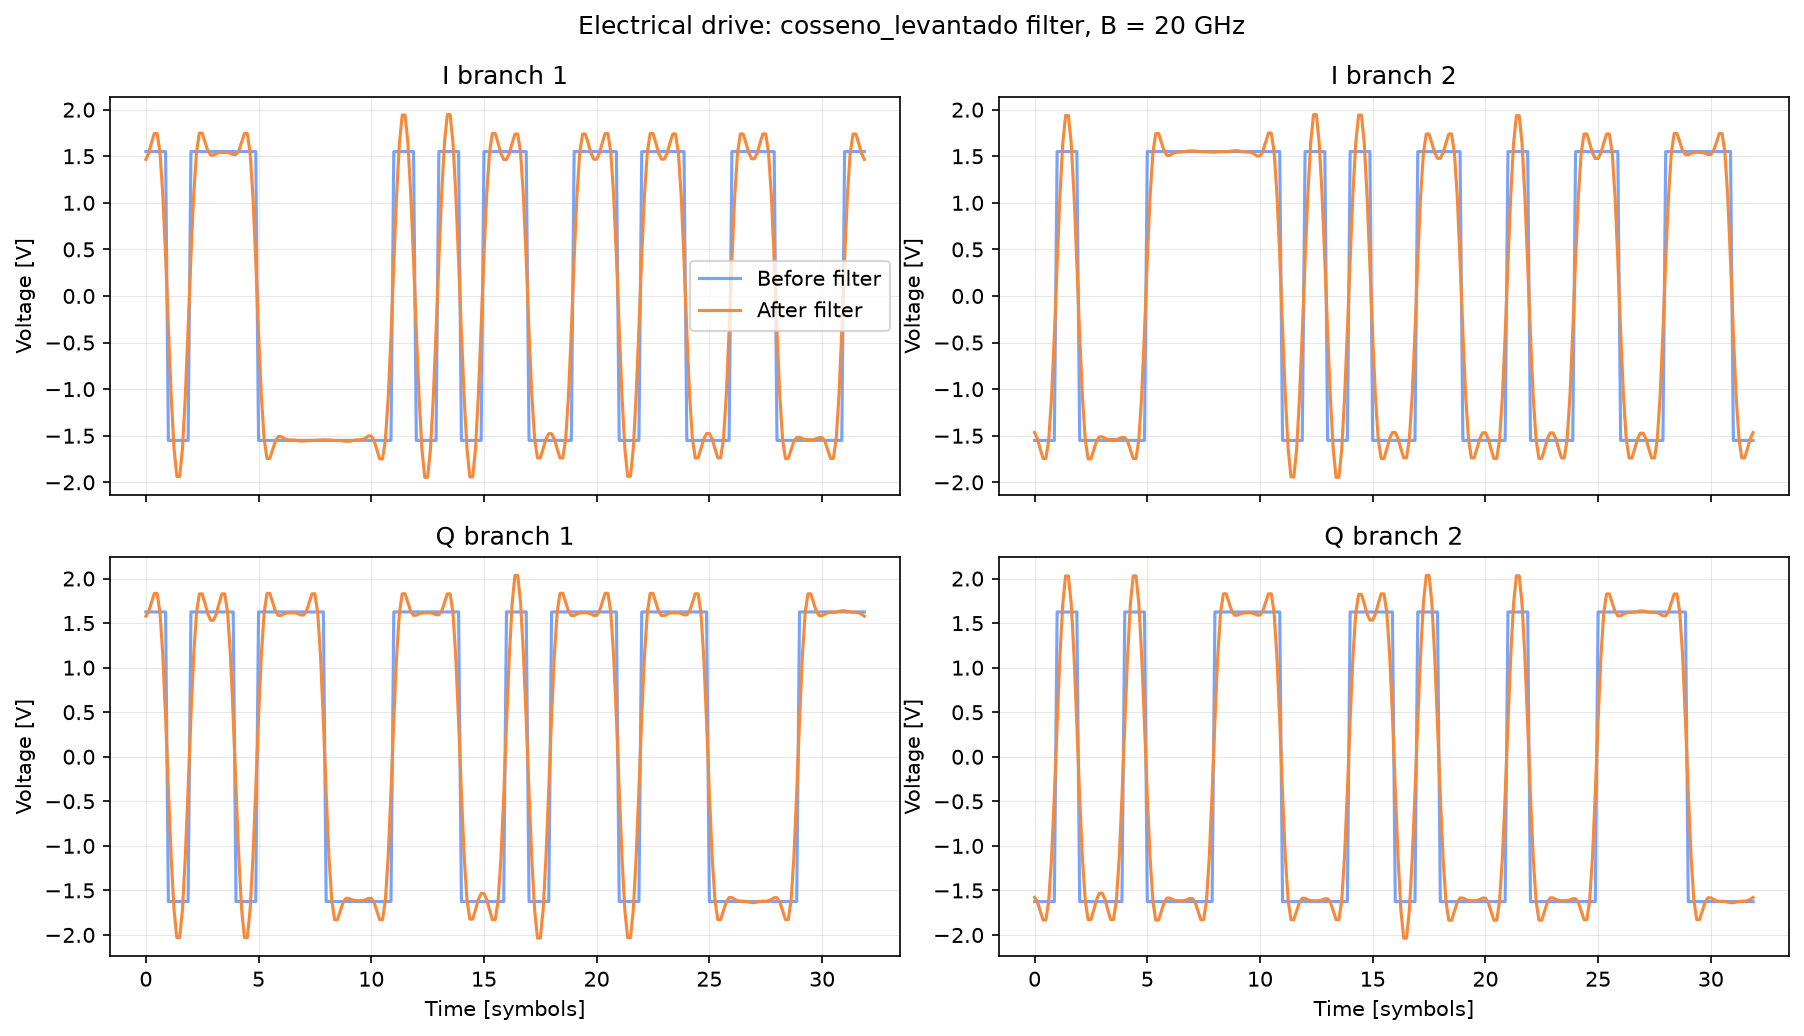

Electrical-drive figure: configured fiber regime is nonlinear (Kerr enabled) (filtering is independent of propagation).


In [3]:
NUM_SYMBOLS_FILTER = 32
filter_symbols, _ = generate_qpsk_symbols(NUM_SYMBOLS_FILTER, seed=42)
active_filter = FILTER_PARAMS if USE_ELECTRICAL_FILTER else None

filter_demo_field, t_filter, dt_filter = modulate_optical_signal(
    filter_symbols, sps=SPS, launch_power_dbm=0.0, symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR, iq_params=IQ_PARAMS, filter_params=active_filter,
    plot_filter=USE_ELECTRICAL_FILTER,
    filter_plot_path=str(ARTIFACT_DIR/'efeito_filtro_drives_eletricos.png') if USE_ELECTRICAL_FILTER else None,
    n_plot=NUM_SYMBOLS_FILTER
)
if USE_ELECTRICAL_FILTER:
    display(Image(filename=str(ARTIFACT_DIR/'efeito_filtro_drives_eletricos.png')))
if not USE_ELECTRICAL_FILTER:
    print('Filter disabled: drive signals were not filtered in this configuration.')
print(f'Electrical-drive figure: configured fiber regime is {REGIME_LABEL} (filtering is independent of propagation).')


## Shared Optical-Link and Training Functions

The fiber is divided into 50 km spans, each followed by an ideal EDFA that compensates its loss. `INCLUDE_KERR` selects `regime=1` (SSFM with Kerr) or `regime=0` (analytical linear propagation). At the receiver, the terminal gain and attenuator set the mean power to the 0 dBm target, as in the earlier studies. This experiment does not include ASE/AWGN.

At each point, PSO runs twice: one objective returns BER after PNN + CDC, and the other returns EVM calculated from the complex symbols sampled after the same chain. `calculate_evm` normalizes power and removes an optimal constant phase. Each set of trained weights is evaluated on an independent test frame.

In [4]:
FS = SPS * SYMBOL_RATE
DT = 1.0 / FS
EDFA_MODEL = EDFAIdeal

def mean_power_dbm(field):
    return 10.0*np.log10(np.mean(np.abs(field)**2)/1e-3)

def propagate_spanned_link(field, t, distance_km):
    n_float = distance_km / SPAN_LENGTH_KM
    n_spans = int(round(n_float))
    if n_spans < 1 or not np.isclose(n_float, n_spans):
        raise ValueError('Distance must be a positive multiple of 50 km.')
    out = np.asarray(field, dtype=complex).copy()
    inline_edfa = EDFA_MODEL(gain_db=FIBER_PARAMS.alpha_db*SPAN_LENGTH_KM)
    regime = 1 if INCLUDE_KERR else 0
    for _ in range(n_spans):
        out, _, _ = fibra_monomodo(
            t, out, wavelength=WAVELENGTH, t0=1.0/SYMBOL_RATE,
            length_km=SPAN_LENGTH_KM, regime=regime, params=FIBER_PARAMS, num_steps=5
        )
        out = inline_edfa.amplify(out)
    return out

def receiver_power_stage(field):
    amplified = EDFA_MODEL(gain_db=RX_EDFA_GAIN_DB).amplify(field)
    attenuation_db = mean_power_dbm(amplified) - RX_TARGET_DBM
    if attenuation_db < -1e-9:
        raise ValueError('Increase RX_EDFA_GAIN_DB to reach the target power.')
    return amplified*10.0**(-max(attenuation_db, 0.0)/20.0)

def make_tx(symbols, launch_power_dbm, seed_for_filter_plot=False):
    params = FILTER_PARAMS if USE_ELECTRICAL_FILTER else None
    field, t, dt = modulate_optical_signal(
        symbols, sps=SPS, launch_power_dbm=launch_power_dbm,
        symbol_rate=SYMBOL_RATE, modulator=MODULATOR, iq_params=IQ_PARAMS,
        filter_params=params, plot_filter=False, n_plot=0
    )
    return field, t, dt

def align_for_evm(tx_symbols, rx_symbols):
    n = min(len(tx_symbols), len(rx_symbols))
    tx = np.asarray(tx_symbols[:n], dtype=complex)
    rx = np.asarray(rx_symbols[:n], dtype=complex)
    tx_norm = tx/(np.sqrt(np.mean(np.abs(tx)**2))+1e-30)
    rx_norm = rx/(np.sqrt(np.mean(np.abs(rx)**2))+1e-30)
    phase = np.angle(np.mean(rx_norm*np.conj(tx_norm)))
    rx_aligned = rx_norm*np.exp(-1j*phase)
    evm = calculate_evm(rx,correct_phase_rotation=correct_phase_rotation)
    return float(evm), tx_norm, rx_aligned

def train_pnn_for_cdc(field_train, phase_lo_train, train_symbols, train_bits, distance_km, objective_type, seed):
    model = PhotonicNeuralNetwork(
        num_channels=PNN_NUM_CHANNELS, base_delay_ps=PNN_BASE_DELAY_PS,
        normalize_power=PNN_NORMALIZE_POWER, responsivity=1.0
    )
    bounds = [(0.0, 1.0)]*PNN_NUM_CHANNELS + [(-np.pi, np.pi)]*PNN_NUM_CHANNELS
    def objective(position):
        model.set_weights(position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:])
        _, field_pnn = model.forward(field_train, dt_s=DT, return_optical_field=True)
        bb = coherent_detection(field_pnn, phase_lo=phase_lo_train)
        bb = cd_compensation(bb, DT, distance_km, dispersion_d=FIBER_PARAMS.d_1550)
        rx_symbols = sample_to_symbols(bb, sps=SPS)
        n = min(len(train_symbols), len(rx_symbols))
        if objective_type == 'BER':
            detected_bits = demap_qpsk(rx_symbols)
            n_bits = min(len(train_bits), len(detected_bits))
            return calculate_ber(train_bits[:n_bits], detected_bits[:n_bits])
        if objective_type == 'EVM':
            return calculate_evm(rx_symbols[:n],correct_phase_rotation=correct_phase_rotation)
        raise ValueError("objective_type deve ser 'BER' ou 'EVM'.")
    return particle_swarm_optimize(
        objective, bounds, swarm_size=PSO_SWARM_SIZE, max_iterations=PSO_ITERATIONS,
        periodic_dimensions=range(PNN_NUM_CHANNELS, 2*PNN_NUM_CHANNELS), seed=seed
    )

def evaluate_pnn_cdc(field_test, phase_lo_test, test_symbols, pso_result, distance_km):
    model = PhotonicNeuralNetwork(
        num_channels=PNN_NUM_CHANNELS, base_delay_ps=PNN_BASE_DELAY_PS,
        normalize_power=PNN_NORMALIZE_POWER, responsivity=1.0
    )
    model.set_weights(pso_result['amplitude_weights'], pso_result['phase_weights'])
    _, field_pnn = model.forward(field_test, dt_s=DT, return_optical_field=True)
    bb = coherent_detection(field_pnn, phase_lo=phase_lo_test)
    bb = cd_compensation(bb, DT, distance_km, dispersion_d=FIBER_PARAMS.d_1550)
    rx_symbols = sample_to_symbols(bb, sps=SPS)
    evm, tx_aligned, rx_aligned = align_for_evm(test_symbols, rx_symbols)
    return evm, tx_aligned, rx_aligned


## QPSK Data and Phase-Noise Realizations

Training and test sequences are independent. For each linewidth, correlated TX/LO phase noise is generated with \(\rho=0.99\). The test realization remains fixed across points in a sweep to reduce random variation when comparing distances or launch powers.

In [5]:
train_symbols, train_bits = generate_qpsk_symbols(NUM_SYMBOLS_TRAIN, seed=PNN_TRAIN_SEED)
test_symbols, test_bits = generate_qpsk_symbols(NUM_SYMBOLS_TEST, seed=PNN_TRAIN_SEED+1)

train_tx_0dbm, t_train, dt_train = make_tx(train_symbols, 0.0)
test_tx_0dbm, t_test, dt_test = make_tx(test_symbols, 0.0)
if not np.isclose(dt_train, DT) or not np.isclose(dt_test, DT):
    raise ValueError('Sampling period is inconsistent with FS.')

phase_data = {}
for idx, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    phase_data[key] = {
        'train': generate_correlated_phases(
            len(t_train), DT, key, correlation_rho=PHASE_CORRELATION_TX_RX,
            seed=TRAIN_PHASE_SEED+idx
        ),
        'test': generate_correlated_phases(
            len(t_test), DT, key, correlation_rho=PHASE_CORRELATION_TX_RX,
            seed=TEST_PHASE_SEED+idx
        ),
    }
print(f'Training frame: {NUM_SYMBOLS_TRAIN} symbols | test frame: {NUM_SYMBOLS_TEST} symbols')


Training frame: 1024 symbols | test frame: 4096 symbols


## Block 2 — EVM vs. Distance

At each distance from 50 to 1000 km and for each linewidth, two independent PSO runs use the same training conditions. One minimizes BER after PNN + CDC; the other minimizes EVM after the same chain. The signal, phase, fiber, and distance are controlled, leaving the PSO objective as the variable under comparison.

Both sets of weights are frozen and evaluated on an independent test frame. EVM is calculated after CDC, with power normalization and optimal constant-phase removal, according to the project metric.

0 kHz |   50 km | BER training | test EVM=35.818% | best training objective=0
0 kHz |   50 km | EVM training | test EVM=12.787% | best training objective=13.4
0 kHz |  100 km | BER training | test EVM=32.780% | best training objective=0
0 kHz |  100 km | EVM training | test EVM=21.905% | best training objective=21.55
0 kHz |  150 km | BER training | test EVM=36.541% | best training objective=0
0 kHz |  150 km | EVM training | test EVM=13.712% | best training objective=13.87
0 kHz |  200 km | BER training | test EVM=33.906% | best training objective=0
0 kHz |  200 km | EVM training | test EVM=9.952% | best training objective=11.58
0 kHz |  250 km | BER training | test EVM=32.607% | best training objective=0
0 kHz |  250 km | EVM training | test EVM=17.354% | best training objective=18.49
0 kHz |  300 km | BER training | test EVM=27.666% | best training objective=0.0004883
0 kHz |  300 km | EVM training | test EVM=20.120% | best training objective=19.42
0 kHz |  350 km | BER training | t

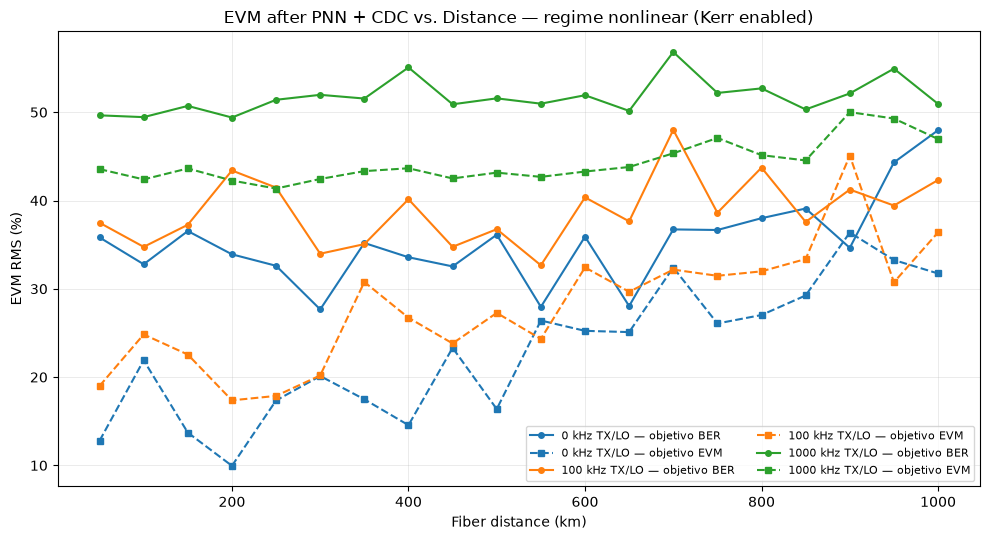

In [6]:
TRAINING_OBJECTIVES = ('BER', 'EVM')
OBJECTIVE_LABELS = {'BER':'objetivo BER', 'EVM':'objetivo EVM'}
OBJECTIVE_STYLES = {'BER':('-', 'o'), 'EVM':('--', 's')}

evm_vs_distance = {
    float(lw): {obj: [] for obj in TRAINING_OBJECTIVES}
    for lw in LINEWIDTHS_HZ
}
constellations_distance = {
    float(lw): {obj: [] for obj in TRAINING_OBJECTIVES}
    for lw in LINEWIDTHS_HZ
}
training_distance = {}

for lw_index, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    phi_tx_train, phi_lo_train = phase_data[key]['train']
    phi_tx_test, phi_lo_test = phase_data[key]['test']
    for distance_index, distance_km in enumerate(DISTANCES_KM):
        tx_train = train_tx_0dbm*np.exp(1j*phi_tx_train)
        tx_test = test_tx_0dbm*np.exp(1j*phi_tx_test)
        field_train = receiver_power_stage(propagate_spanned_link(tx_train, t_train, float(distance_km)))
        field_test = receiver_power_stage(propagate_spanned_link(tx_test, t_test, float(distance_km)))

        for objective_index, objective_type in enumerate(TRAINING_OBJECTIVES):
            seed = PNN_TRAIN_SEED + 10000*distance_index + 100*lw_index + objective_index
            pso = train_pnn_for_cdc(
                field_train, phi_lo_train, train_symbols, train_bits,
                float(distance_km), objective_type, seed
            )
            evm, tx_ref, rx_aligned = evaluate_pnn_cdc(
                field_test, phi_lo_test, test_symbols, pso, float(distance_km)
            )
            evm_vs_distance[key][objective_type].append(evm)
            constellations_distance[key][objective_type].append({'tx':tx_ref, 'rx':rx_aligned})
            training_distance[(float(distance_km), key, objective_type)] = {
                'best_training_objective':float(pso['best_fitness']),
                'evaluations':int(pso['evaluations']),
                'amplitude_weights':pso['amplitude_weights'].copy(),
                'phase_weights':pso['phase_weights'].copy(),
            }
            print(
                f'{key/1e3:g} kHz | {distance_km:4.0f} km | {objective_type} training '
                f'| test EVM={evm:.3f}% | best training objective={pso["best_fitness"]:.4g}'
            )

colors = ['tab:blue', 'tab:orange', 'tab:green']
fig, ax = plt.subplots(figsize=(10, 5.5))
for linewidth_hz, color in zip(LINEWIDTHS_HZ, colors):
    key = float(linewidth_hz)
    for objective_type in TRAINING_OBJECTIVES:
        linestyle, marker = OBJECTIVE_STYLES[objective_type]
        ax.plot(
            DISTANCES_KM, evm_vs_distance[key][objective_type],
            color=color, linestyle=linestyle, marker=marker, markersize=4,
            label=f'{key/1e3:g} kHz TX/LO — {OBJECTIVE_LABELS[objective_type]}'
        )
ax.set(xlabel='Fiber distance (km)', ylabel='EVM RMS (%)',
       title=f'EVM after PNN + CDC vs. Distance — regime {REGIME_LABEL}')
ax.grid(True, alpha=.35); ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR/'evm_pnn_cdc_por_distancia_objetivos_ber_evm.png', dpi=250, bbox_inches='tight')
plt.show()


## Block 3 — EVM vs. Launch Power

The link distance is fixed at 1000 km, while launch power varies from −20 to +20 dBm in 2 dB steps. At each power and linewidth, two PNNs are trained: one minimizes BER and the other minimizes EVM after PNN + conventional CDC. Both are evaluated by EVM on the same independent test frame.

The fiber regime follows `INCLUDE_KERR`. With Kerr enabled, launch power changes the accumulated nonlinear phase. With Kerr disabled and no additive noise, EVM is expected to have little physical dependence on launch power, apart from model and optimization effects.

0 kHz | -20.0 dBm | BER training | test EVM=31.948% | best training objective=0
0 kHz | -20.0 dBm | EVM training | test EVM=17.008% | best training objective=16.56
0 kHz | -18.0 dBm | BER training | test EVM=37.511% | best training objective=0
0 kHz | -18.0 dBm | EVM training | test EVM=24.070% | best training objective=24.19
0 kHz | -16.0 dBm | BER training | test EVM=34.619% | best training objective=0
0 kHz | -16.0 dBm | EVM training | test EVM=29.374% | best training objective=28.65
0 kHz | -14.0 dBm | BER training | test EVM=36.652% | best training objective=0
0 kHz | -14.0 dBm | EVM training | test EVM=6.775% | best training objective=8.668
0 kHz | -12.0 dBm | BER training | test EVM=27.811% | best training objective=0
0 kHz | -12.0 dBm | EVM training | test EVM=15.931% | best training objective=17.07
0 kHz | -10.0 dBm | BER training | test EVM=35.693% | best training objective=0.0004883
0 kHz | -10.0 dBm | EVM training | test EVM=17.790% | best training objective=18.18
0 kHz |  

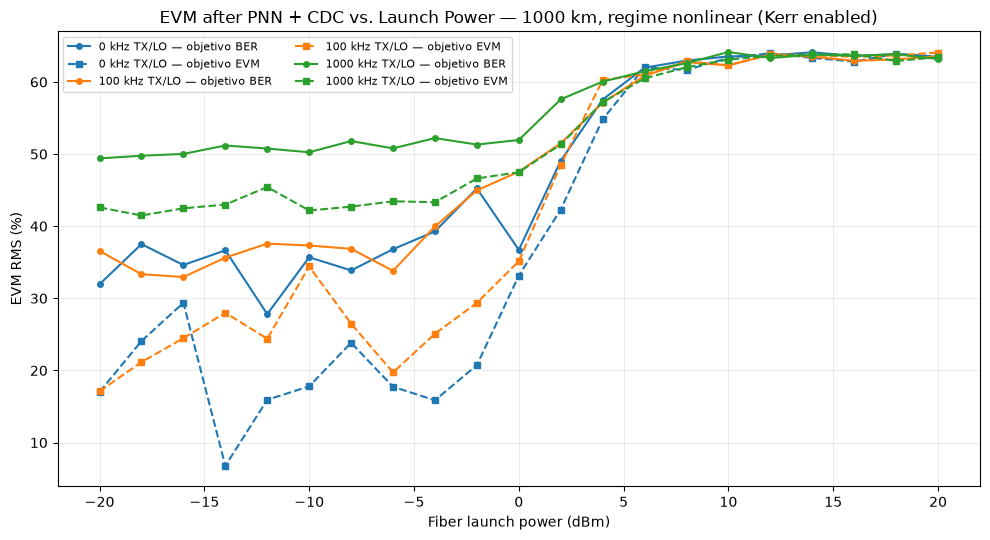

In [7]:
evm_vs_power = {
    float(lw): {obj: [] for obj in TRAINING_OBJECTIVES}
    for lw in LINEWIDTHS_HZ
}
constellations_power = {
    float(lw): {obj: [] for obj in TRAINING_OBJECTIVES}
    for lw in LINEWIDTHS_HZ
}
training_power = {}

for lw_index, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    phi_tx_train, phi_lo_train = phase_data[key]['train']
    phi_tx_test, phi_lo_test = phase_data[key]['test']
    for power_index, launch_power_dbm in enumerate(POWER_SWEEP_DBM):
        # Phase realizations are shared across all power values within a linewidth.
        train_base, _, _ = make_tx(train_symbols, float(launch_power_dbm))
        test_base, _, _ = make_tx(test_symbols, float(launch_power_dbm))
        tx_train = train_base*np.exp(1j*phi_tx_train)
        tx_test = test_base*np.exp(1j*phi_tx_test)
        field_train = receiver_power_stage(
            propagate_spanned_link(tx_train, t_train, POWER_SWEEP_DISTANCE_KM)
        )
        field_test = receiver_power_stage(
            propagate_spanned_link(tx_test, t_test, POWER_SWEEP_DISTANCE_KM)
        )

        for objective_index, objective_type in enumerate(TRAINING_OBJECTIVES):
            seed = PNN_TRAIN_SEED + 500000 + 10000*power_index + 100*lw_index + objective_index
            pso = train_pnn_for_cdc(
                field_train, phi_lo_train, train_symbols, train_bits,
                POWER_SWEEP_DISTANCE_KM, objective_type, seed
            )
            evm, tx_ref, rx_aligned = evaluate_pnn_cdc(
                field_test, phi_lo_test, test_symbols, pso, POWER_SWEEP_DISTANCE_KM
            )
            evm_vs_power[key][objective_type].append(evm)
            constellations_power[key][objective_type].append({'tx':tx_ref, 'rx':rx_aligned})
            training_power[(float(launch_power_dbm), key, objective_type)] = {
                'best_training_objective':float(pso['best_fitness']),
                'evaluations':int(pso['evaluations']),
                'amplitude_weights':pso['amplitude_weights'].copy(),
                'phase_weights':pso['phase_weights'].copy(),
            }
            print(
                f'{key/1e3:g} kHz | {launch_power_dbm:5.1f} dBm | {objective_type} training '
                f'| test EVM={evm:.3f}% | best training objective={pso["best_fitness"]:.4g}'
            )

fig, ax = plt.subplots(figsize=(10, 5.5))
for linewidth_hz, color in zip(LINEWIDTHS_HZ, colors):
    key = float(linewidth_hz)
    for objective_type in TRAINING_OBJECTIVES:
        linestyle, marker = OBJECTIVE_STYLES[objective_type]
        ax.plot(
            POWER_SWEEP_DBM, evm_vs_power[key][objective_type],
            color=color, linestyle=linestyle, marker=marker, markersize=4,
            label=f'{key/1e3:g} kHz TX/LO — {OBJECTIVE_LABELS[objective_type]}'
        )
ax.set(xlabel='Fiber launch power (dBm)', ylabel='EVM RMS (%)',
       title=f'EVM after PNN + CDC vs. Launch Power — {POWER_SWEEP_DISTANCE_KM:g} km, regime {REGIME_LABEL}')
ax.grid(True, alpha=.35); ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR/'evm_pnn_cdc_por_potencia_objetivos_ber_evm.png', dpi=250, bbox_inches='tight')
plt.show()


## Block 4 — Constellations at the Best and Worst Points

For each linewidth and training objective, the lowest-EVM point (“best case”) and highest-EVM point (“worst case”) are selected independently for each analysis. Each figure has 12 panels: three linewidths × two objectives × best/worst case. Received symbols in each panel are normalized and aligned by constant gain and phase for direct comparison with the transmitted QPSK reference.

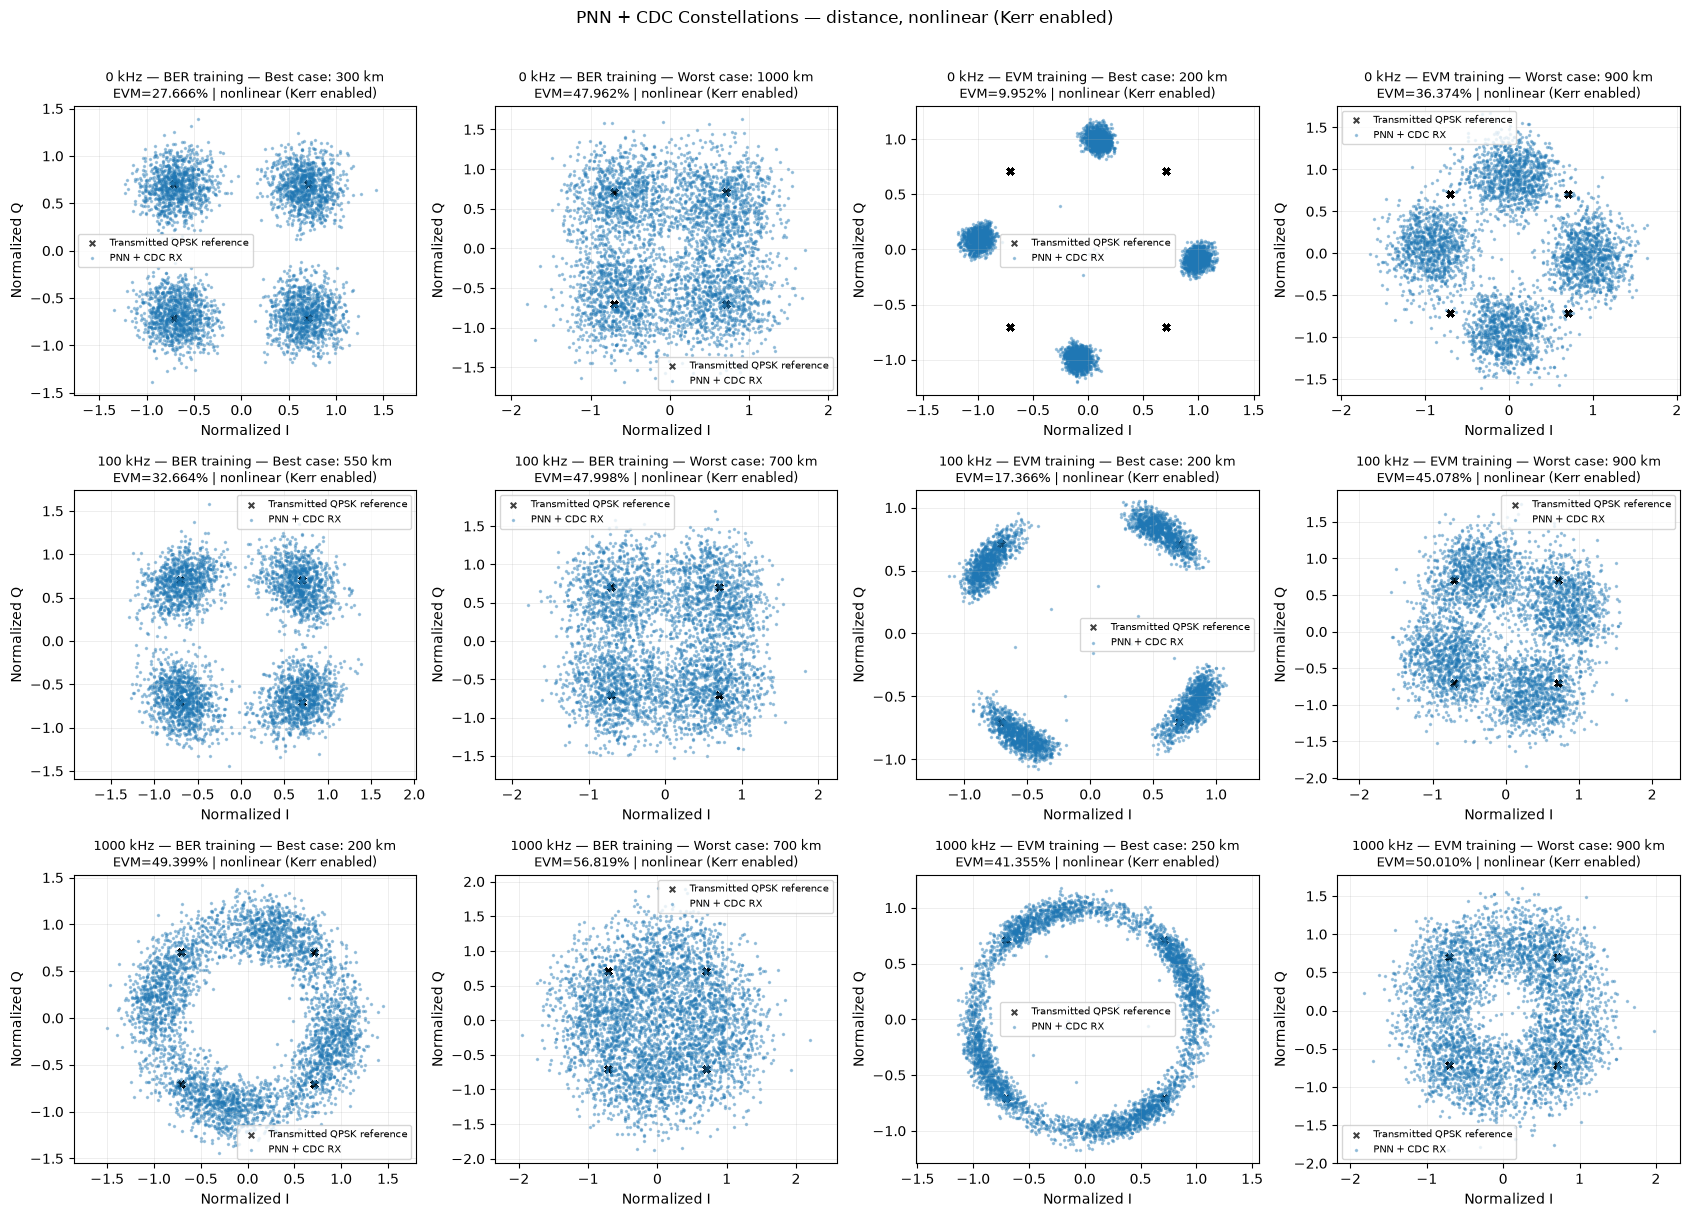

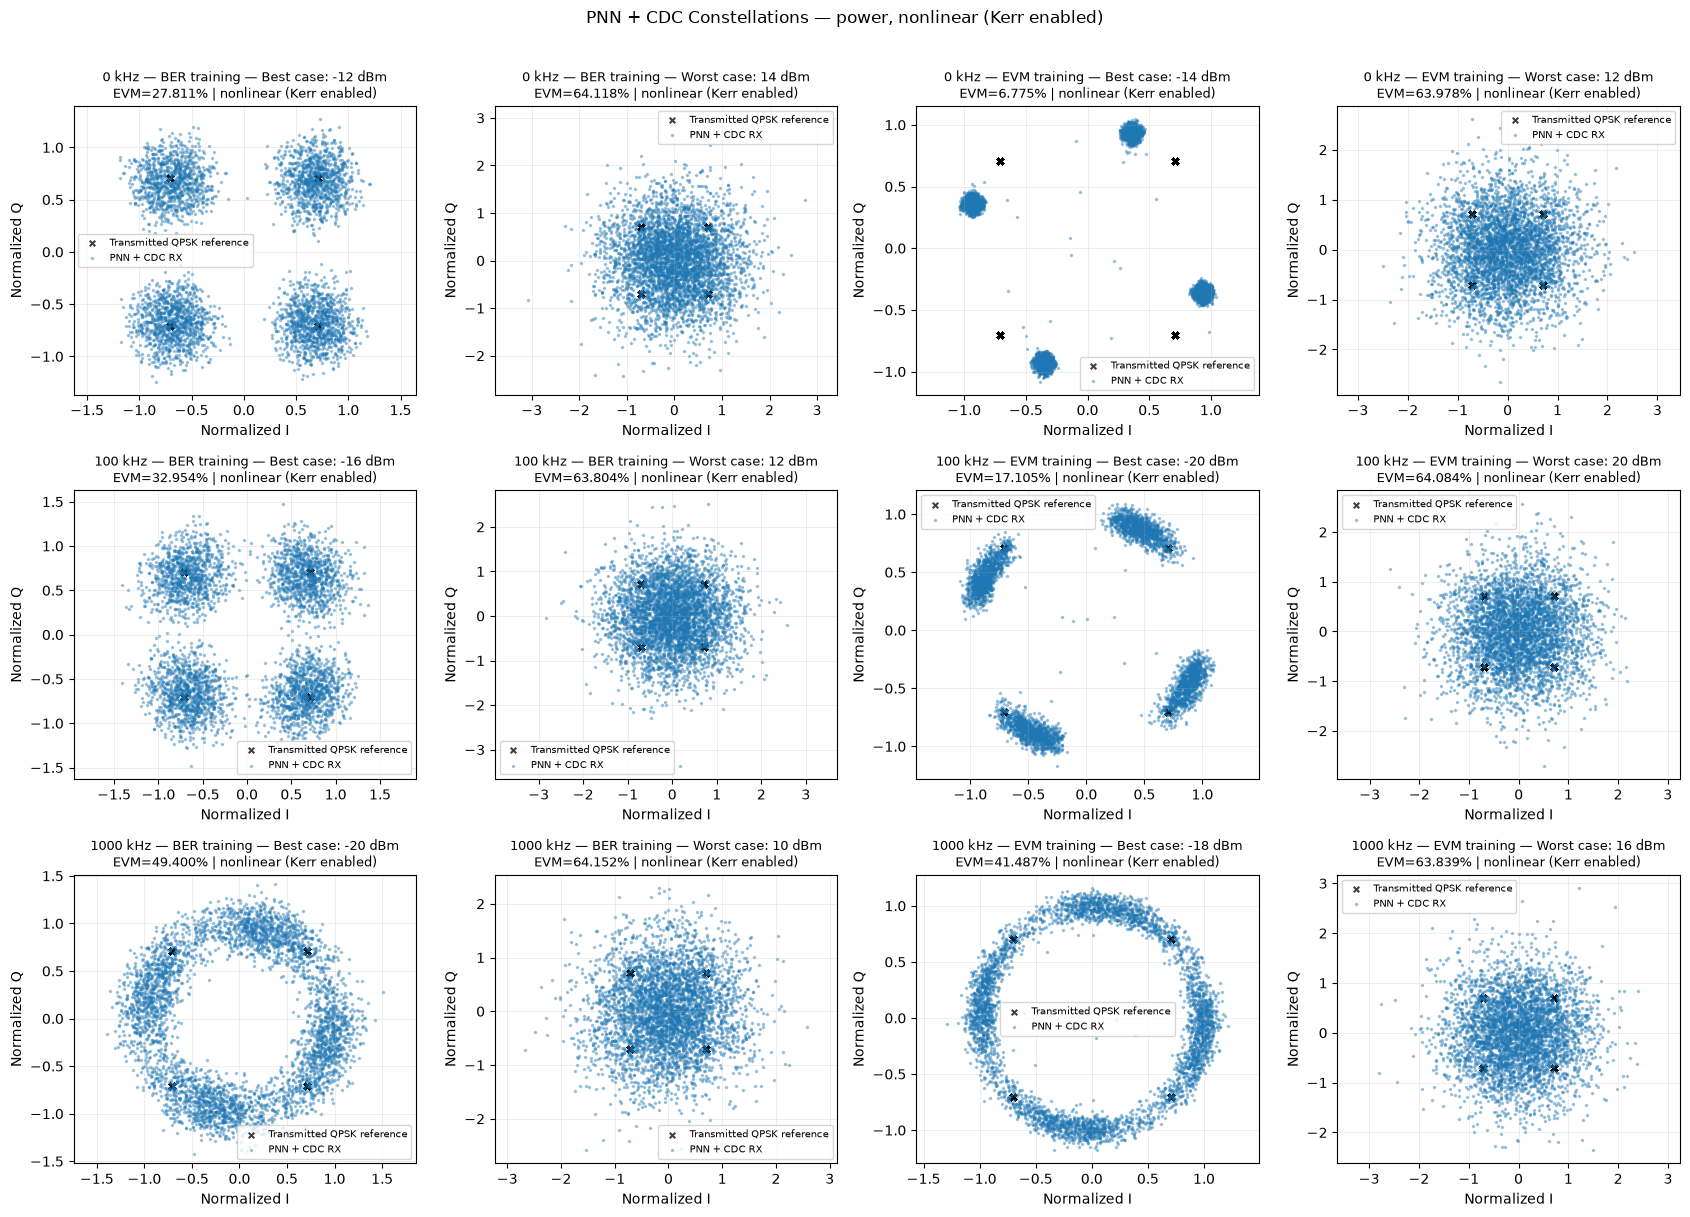

In [8]:
def plot_best_worst_constellations(x_values, evm_curves, constellation_data, sweep_name, file_name):
    fig, axes = plt.subplots(len(LINEWIDTHS_HZ), 4, figsize=(17, 12))
    columns = [
        ('BER', 'Best case'), ('BER', 'Worst case'),
        ('EVM', 'Best case'), ('EVM', 'Worst case'),
    ]
    for row, linewidth_hz in enumerate(LINEWIDTHS_HZ):
        key = float(linewidth_hz)
        for col, (objective_type, case_label) in enumerate(columns):
            values = np.asarray(evm_curves[key][objective_type], dtype=float)
            idx = int(np.nanargmin(values) if case_label == 'Best case' else np.nanargmax(values))
            ax = axes[row, col]
            data = constellation_data[key][objective_type][idx]
            ax.scatter(data['tx'].real, data['tx'].imag, s=16, marker='x',
                       color='black', alpha=.75, label='Transmitted QPSK reference')
            ax.scatter(data['rx'].real, data['rx'].imag, s=9, marker='.',
                       color='tab:blue', alpha=.35, label='PNN + CDC RX')
            point_text = f'{x_values[idx]:g} km' if sweep_name == 'distance' else f'{x_values[idx]:g} dBm'
            ax.set_title(
                f'{linewidth_hz/1e3:g} kHz — {objective_type} training — {case_label}: '
                f'{point_text}\nEVM={values[idx]:.3f}% | {REGIME_LABEL}', fontsize=9
            )
            ax.set_xlabel('Normalized I'); ax.set_ylabel('Normalized Q')
            ax.set_aspect('equal', adjustable='datalim'); ax.grid(True, alpha=.3)
            ax.legend(fontsize=7, loc='best')
    fig.suptitle(f'PNN + CDC Constellations — {sweep_name}, {REGIME_LABEL}', y=1.01)
    fig.tight_layout()
    fig.savefig(ARTIFACT_DIR/file_name, dpi=250, bbox_inches='tight')
    plt.show()
    return fig

fig_distance_constellations = plot_best_worst_constellations(
    DISTANCES_KM, evm_vs_distance, constellations_distance,
    'distance', 'constelacoes_pnn_cdc_distancia_objetivos_ber_evm.png'
)
fig_power_constellations = plot_best_worst_constellations(
    POWER_SWEEP_DBM, evm_vs_power, constellations_power,
    'power', 'constelacoes_pnn_cdc_potencia_objetivos_ber_evm.png'
)


## Notes for Interpretation

- Both objectives use the same training frame, propagation, PNN, and CDC. The only difference is the scalar minimized by PSO: BER after decisions/demapping or complex EVM before decisions.
- `calculate_evm` normalizes power and removes an optimal constant phase during both EVM-based training and evaluation. No timing search or time-varying phase recovery is performed in DSP.
- Weights are evaluated on test sequences independent of those used for optimization. Test EVM is the common metric for comparing objectives.
- With `INCLUDE_KERR=True`, figures identify the nonlinear regime. Changing it to `False` requires rerunning propagation, training, and plotting cells.
- The model adds no ASE/AWGN. Therefore, the power sweep with Kerr disabled does not model OSNR degradation with launch power.
- The electrical-filter figure compares drive signals before and after the raised-cosine filter in `FILTER_PARAMS`; it does not show the optical spectrum after the fiber.
- PSO performs `PSO_SWARM_SIZE × (PSO_ITERATIONS + 1)` evaluations per training. With 20 distances, 21 power points, three linewidths, and two objectives, this totals 246 trainings. Smaller swarms and fewer iterations speed up exploration; use multiple PSO seeds for conclusive comparisons.